In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay
)

import joblib

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
df = pd.read_csv(
    "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
)

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = df[features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Data ready!")
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Data ready!
Training: (712, 7)
Testing: (179, 7)


In [6]:
numeric = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical = ["Sex", "Embarked"]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss")
}

print("4 models ready!")


4 models ready!


In [5]:
from xgboost import XGBClassifier

print("XGBoost ready!")

XGBoost ready!


In [7]:
results = {}

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    }

results_df = pd.DataFrame(results).T

display(results_df)

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.804469,0.793103,0.666667,0.724409,0.843742
Random Forest,0.815642,0.800000,0.695652,0.744186,0.828722
Gradient Boosting,0.798883,0.789474,0.652174,0.714286,0.818050
XGBoost,0.798883,0.746269,0.724638,0.735294,0.809223


In [9]:
best_models = {}

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    grid = GridSearchCV(
        pipe,
        {},
        cv=5,
        scoring="roc_auc"
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid

best_name = max(
    best_models,
    key=lambda x: best_models[x].best_score_
)

champion = best_models[best_name].best_estimator_

print("Champion Model:", best_name)
print("Best CV ROC-AUC:", best_models[best_name].best_score_)

Champion Model: Gradient Boosting
Best CV ROC-AUC: 0.8768137355794096


<Figure size 800x600 with 0 Axes>

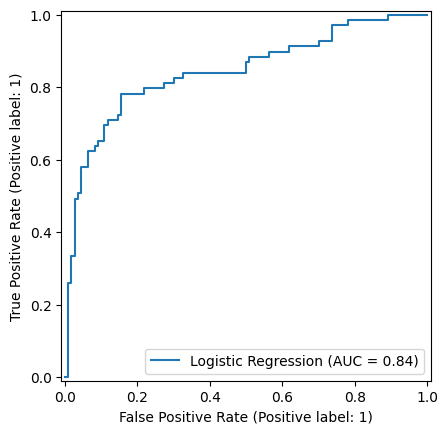

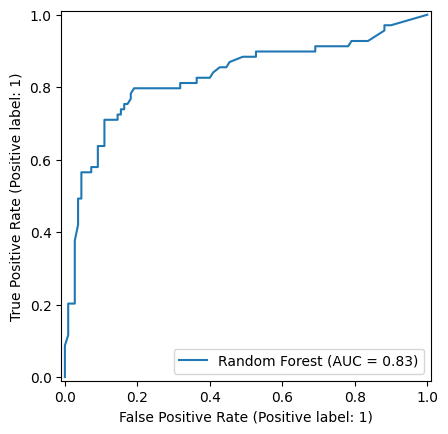

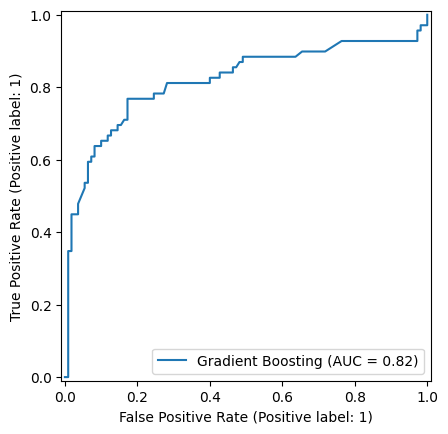

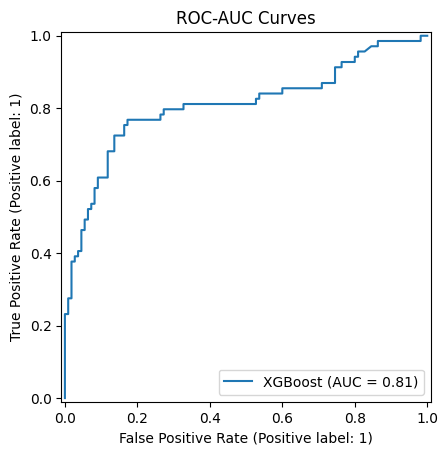

CHAMPION MODEL: Gradient Boosting

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.89      0.84       110
           1       0.79      0.65      0.71        69

    accuracy                           0.80       179
   macro avg       0.80      0.77      0.78       179
weighted avg       0.80      0.80      0.79       179


Confusion Matrix:
[[98 12]
 [24 45]]

Champion model saved as champion_model.joblib


In [10]:
plt.figure(figsize=(8, 6))

for name, model in best_models.items():
    prob = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, prob, name=name)

plt.title("ROC-AUC Curves")
plt.show()

pred = champion.predict(X_test)

print("CHAMPION MODEL:", best_name)
print("\nClassification Report:")
print(classification_report(y_test, pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred))

joblib.dump(champion, "champion_model.joblib")

print("\nChampion model saved as champion_model.joblib")